# LAB 2 for CS4243: Perspective-Aware Virtual Advertisement Overlay
## Notebook 3 — Occlusion handling and compositing
> **Introduction.** This notebook develops **Stage 3 (Composite)** in `overlaylab/compositing.py`. Hysteresis thresholds
> and the minimum component area are chosen on the three **validation** masks of the common clip only
> (`select_difference_thresholds`), frozen, and reported on the three **test** masks of the common clip, on the mask
> frames of the combined and viewpoint clips (section 6) and later on your personal audit masks. The cells marked
> **REQUIRED** must be completed.

## 1. Imports, the six mask frames, and their homographies
The ground-truth masks may be used only to *select thresholds* (validation) and to *evaluate* (test). The homography of
each mask frame comes from your own `localise_board`, never from the ground-truth corners.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
import cv2

from overlaylab import data, metrics, visualize as viz
from overlaylab import supplied as sp
from overlaylab.config import notebook_config, replace
from overlaylab.localisation import localise_board, artwork_to_frame
from overlaylab.compositing import hysteresis, compensated_difference, occlusion_mask, select_difference_thresholds, composite
from overlaylab.geometry import warp_artwork
import json

from overlaylab.config import PipelineConfig
threshold_path = ROOT / "outputs" / "thresholds.json"
assert threshold_path.exists(), "run Notebook 2 first to freeze Stage 1 and 2"
config = PipelineConfig.from_json(threshold_path.read_text())
config.resize_width = data.NOTEBOOK_WIDTH
# min_area in the saved file is at original-video resolution.
config.occlusion.min_area = max(1, int(round(config.occlusion.min_area * (data.NOTEBOOK_WIDTH / sp.video_info(data.COMMON_CLIP)["width"]) ** 2)))
reference_full = data.load_reference()
width = data.NOTEBOOK_WIDTH; factor = width / sp.video_info(data.COMMON_CLIP)["width"]
reference = sp.resize_width(reference_full, int(round(reference_full.shape[1] * factor)))
config.localisation.warp.reference_shape = reference.shape[:2]
artwork = data.load_artwork("ad")
masks_val = data.load_gt_masks("validation", width=width); masks_test = data.load_gt_masks("test", width=width)
mask_frames = {}
for i, f in sp.iter_video(data.COMMON_CLIP, step=1, width=width, start=min(masks_val | masks_test), stop=max(masks_val | masks_test) + 1):
    if i in masks_val or i in masks_test:
        mask_frames[i] = f
homs = {i: localise_board(reference, mask_frames[i], config.localisation)[0] for i in mask_frames}
assert all(homs[i] is not None for i in masks_val), "validation localisation failed; investigate Stage 1 on validation data before threshold search"
print("validation masks:", sorted(masks_val), " test masks:", sorted(masks_test), " localised:", [i for i in homs if homs[i] is not None])

validation masks: [96, 192, 272]  test masks: [144, 208, 448]  localised: [96, 144, 192, 208, 272, 448]


## 2. The motion-compensated difference
Warp the reference into the frame, fit a global gain and offset on the best-agreeing pixels, and look at the difference
map. Illumination change alone should *not* light up; the card crossing the poster should.

frame 96: fitted gain 0.961, offset 0.002


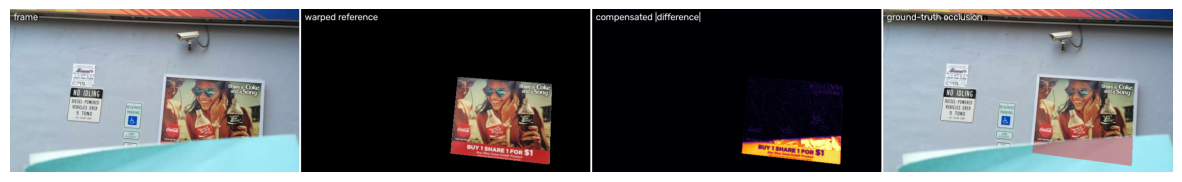

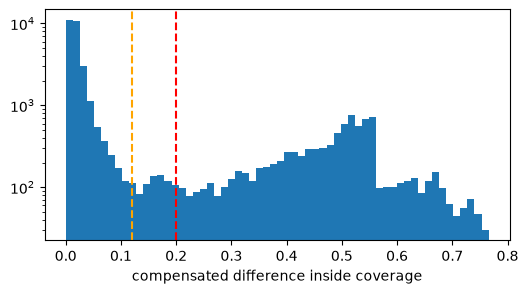

In [2]:
i = sorted(masks_val)[0]
warped_ref, cov = warp_artwork(reference, homs[i], mask_frames[i].shape)
diff, (gain, offset) = compensated_difference(mask_frames[i], warped_ref, cov, config.occlusion)
print(f"frame {i}: fitted gain {gain:.3f}, offset {offset:.3f}")
plt.figure(figsize=(15, 4)); plt.imshow(viz.montage([viz.label(mask_frames[i], "frame"), viz.label(warped_ref, "warped reference"), viz.label(viz.heatmap(diff, 0.6), "compensated |difference|"), viz.label(viz.overlay_mask(mask_frames[i], masks_val[i]), "ground-truth occlusion")], cols=4)); plt.axis("off"); plt.show()
plt.figure(figsize=(6, 3)); plt.hist(diff[cov], bins=60, log=True); plt.axvline(config.occlusion.weak, color="orange", ls="--"); plt.axvline(config.occlusion.strong, color="red", ls="--"); plt.xlabel("compensated difference inside coverage"); plt.show()

## 3. Select the thresholds on the validation masks (REQUIRED)
`select_difference_thresholds` must search strong / weak / minimum-area settings on the **validation** masks only and
return the frozen configuration. Record the frozen values in `outputs/thresholds.json`. The minimum area is a pixel
count, so it is stored at full resolution (scaled by `1 / factor**2`); `run_pipeline` rescales it when you pass `--width`.

In [3]:
# Select and freeze thresholds using validation frames only; inspect the search log.
val_inputs = [(mask_frames[i], homs[i], reference) for i in sorted(masks_val)]
frozen_occ, log = select_difference_thresholds(val_inputs, [masks_val[i] for i in sorted(masks_val)], config.occlusion)
best = sorted(log, key=lambda r: -r["mean_iou"])[:5]
print("top settings on validation:"); [print("  ", r) for r in best]
config.occlusion = frozen_occ
from overlaylab.config import PipelineConfig
path = ROOT / "outputs" / "thresholds.json"
merged = PipelineConfig.from_json(path.read_text()) if path.exists() else PipelineConfig()   # keep Notebook 2's decisions
merged.occlusion = replace(frozen_occ, min_area=int(round(frozen_occ.min_area / factor ** 2)))   # min_area is stored at full resolution
path.write_text(json.dumps(merged.thresholds(), indent=2)); print("frozen (min_area at full resolution):", merged.thresholds()["occlusion"])

top settings on validation:
   {'strong': 0.15, 'weak': 0.12, 'min_area': 19, 'mean_iou': 0.9023661160011893}
   {'strong': 0.15, 'weak': 0.12, 'min_area': 38, 'mean_iou': 0.9023661160011893}
   {'strong': 0.15, 'weak': 0.12, 'min_area': 76, 'mean_iou': 0.9023661160011893}
   {'strong': 0.2, 'weak': 0.12, 'min_area': 19, 'mean_iou': 0.9023661160011893}
   {'strong': 0.2, 'weak': 0.12, 'min_area': 38, 'mean_iou': 0.9023661160011893}
frozen (min_area at full resolution): {'mode': 'difference', 'strong': 0.2, 'weak': 0.12, 'min_area': 152, 'open_radius': 2, 'connectivity': 8, 'gain_quantile': 0.5, 'feather': 3}


## 4. Report on the test masks against the no-occlusion baseline (REQUIRED)
IoU, F1, foreground leakage and boundary F1 per test frame, and the same numbers for a baseline that paints the whole board.

frame    IoU     F1  boundary  leakage  baseline leakage
  144  0.924  0.960     0.673    0.009             0.934
  208  0.950  0.975     0.926    0.007             0.964
  448  0.806  0.892     0.416    0.006             0.828


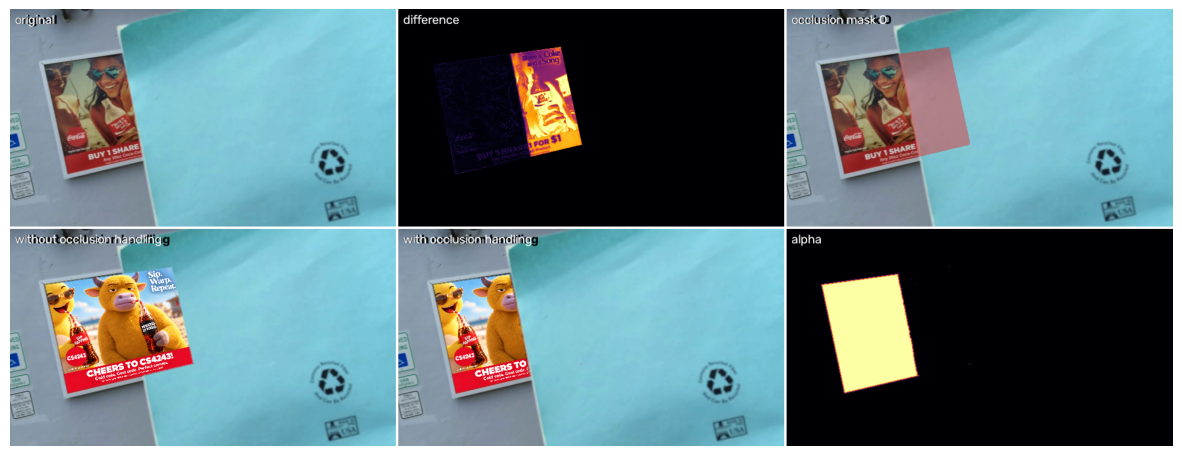

component statistics [label, x, y, w, h, area]:
[[    1   186    62   118   182 14666]]


In [4]:
# Evaluate test masks with the frozen configuration against the paint-whole-board baseline.
print(f"{'frame':>5s} {'IoU':>6s} {'F1':>6s} {'boundary':>9s} {'leakage':>8s} {'baseline leakage':>17s}")
rows = []
for i in sorted(masks_test):
    if homs[i] is None:
        print(f"{i:5d}: localisation failed; report as hidden, do not replace with ground truth")
        continue
    m, dmap, comp = occlusion_mask(mask_frames[i], homs[i], reference, config.occlusion)
    Ha = artwork_to_frame(artwork, homs[i], config.localisation); warped, cov = warp_artwork(artwork, Ha, mask_frames[i].shape)
    out, alpha = composite(mask_frames[i], warped, cov, m, config.composite)
    base, alpha_base = composite(mask_frames[i], warped, cov, np.zeros_like(m), config.composite)
    rows.append((i, metrics.mask_iou(m, masks_test[i]), metrics.mask_f1(m, masks_test[i]), metrics.boundary_f1(m, masks_test[i]),
                 metrics.leakage(alpha, masks_test[i]), metrics.leakage(alpha_base, masks_test[i])))
    print(f"{i:5d} {rows[-1][1]:6.3f} {rows[-1][2]:6.3f} {rows[-1][3]:9.3f} {rows[-1][4]:8.3f} {rows[-1][5]:17.3f}")
i = next((i for i in sorted(masks_test) if homs[i] is not None), None)
assert i is not None, "all test localisations failed; report that failure and analyse Stage 1 evidence"
m, dmap, comp = occlusion_mask(mask_frames[i], homs[i], reference, config.occlusion)
Ha = artwork_to_frame(artwork, homs[i], config.localisation); warped, cov = warp_artwork(artwork, Ha, mask_frames[i].shape)
out, alpha = composite(mask_frames[i], warped, cov, m, config.composite); base, _ = composite(mask_frames[i], warped, cov, np.zeros_like(m), config.composite)
plt.figure(figsize=(15, 6)); plt.imshow(viz.montage([viz.label(mask_frames[i], "original"), viz.label(viz.heatmap(dmap, 0.6), "difference"), viz.label(viz.overlay_mask(mask_frames[i], m), "occlusion mask O"), viz.label(base, "without occlusion handling"), viz.label(out, "with occlusion handling"), viz.label(viz.heatmap(alpha, 1.0), "alpha")], cols=3)); plt.axis("off"); plt.show()
print("component statistics [label, x, y, w, h, area]:"); print(comp)

## 5. What the thresholds and the hysteresis step do (**Question 4**)
Sweep the strong threshold and the minimum area on one validation frame and watch the mask and the leakage change; do not use test results to change the frozen settings; disable
hysteresis (weak = strong) to see what happens along the card's edge, where the difference fades through the motion blur.

In [5]:
i = sorted(masks_val)[1]
Ha = artwork_to_frame(artwork, homs[i], config.localisation); warped, cov = warp_artwork(artwork, Ha, mask_frames[i].shape)
print(f"{'strong':>6s} {'weak':>5s} {'min_area':>8s} {'IoU':>6s} {'leakage':>8s} {'mask px':>8s}")
for strong, weak, area in [(config.occlusion.strong, config.occlusion.weak, config.occlusion.min_area),
                           (config.occlusion.strong * 1.5, config.occlusion.weak, config.occlusion.min_area),
                           (config.occlusion.strong, config.occlusion.weak, config.occlusion.min_area * 6),
                           (config.occlusion.strong, config.occlusion.strong, config.occlusion.min_area)]:
    m, _, _ = occlusion_mask(mask_frames[i], homs[i], reference, replace(config.occlusion, strong=strong, weak=weak, min_area=area))
    _, alpha = composite(mask_frames[i], warped, cov, m, config.composite)
    print(f"{strong:6.2f} {weak:5.2f} {area:8d} {metrics.mask_iou(m, masks_val[i]):6.3f} {metrics.leakage(alpha, masks_val[i]):8.3f} {int(m.sum()):8d}")

strong  weak min_area    IoU  leakage  mask px
  0.20  0.12       38  0.903    0.001    15873
  0.30  0.12       38  0.903    0.001    15873
  0.20  0.12      228  0.903    0.001    15873
  0.20  0.20       38  0.671    0.201    11249


## 6. EVALUATION-ONLY GT-FALLBACK — the combined and viewpoint clips with the frozen thresholds (REQUIRED)
The Stage 3 stress clips, `data.stress_clips(3)`. `manifests/diagnostic_masks.csv` lists the mask frames of the
**combined** clip (the blue card crosses the poster while the camera rotates) and of the **viewpoint** clip (three
strong-keystone frames with an *empty* mask: nothing is in front of the board). With the configuration frozen above:

* **combined**: mask IoU / F1 / leakage on the six mask frames against the no-occlusion baseline, as in section 4.
* **viewpoint**: the **false-occlusion fraction** = fraction of the (visible) board that the mask wrongly removes when
  nothing occludes it; the no-occlusion baseline is 0 % false occlusion by construction. Here the homography is always
  available (frozen or GT-fallback), so the overlay is present on every mask frame and the number is a mean over all
  three mask frames. `overlaylab.evaluate` estimates an output-pixel-change proxy on a *finished video*, only on mask frames where
  it detects the artwork in the output: frames where the overlay is absent (hidden by the monitor, tracker lost) are
  listed as `overlay_absent_frames` and excluded, and the printed line says how many frames the mean is based on. The proxy also includes feathering, resampling and similar artwork colours, so it need not equal the direct mask fraction. Always
  quote the frame count with the number. The full-resolution Stage 3 table comes from `python -m overlaylab.report`.

The homography of each frame comes from your `localise_board` with the frozen configuration. When it fails or exceeds the frozen corner-error threshold on a mask frame
(the card covers most of the poster on some combined-clip frames), the cell falls back to the manifest corners through
`cv2.getPerspectiveTransform` **for the mask evaluation only** and labels the row `GT-fallback`; say so in the report and
never use that fallback anywhere else. **Question 4** asks why the viewpoint clip produces false occlusion under strong
perspective even when the homography is correct.

     clip frame           H    IoU     F1  leakage base leak false occ coverage
 combined   212 GT-fallback  0.961  0.980    0.001     0.974     0.012    0.946
 combined   216      frozen  0.969  0.984    0.002     0.971     0.008    0.942
 combined   220      frozen  0.970  0.985    0.004     0.970     0.003    0.959
 combined   304      frozen  0.885  0.939    0.000     0.982     0.020    0.915
 combined   306      frozen  0.942  0.970    0.000     0.937     0.007    0.938
 combined   314      frozen  0.903  0.949    0.000     0.974     0.016    0.927


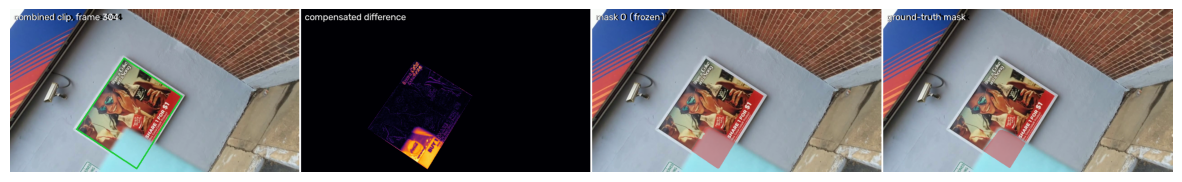

viewpoint   128      frozen    n/a    n/a    n/a    n/a     0.000    0.968
viewpoint   224 GT-fallback    n/a    n/a    n/a    n/a     0.043    0.907
viewpoint   288 GT-fallback    n/a    n/a    n/a    n/a     0.019    0.916


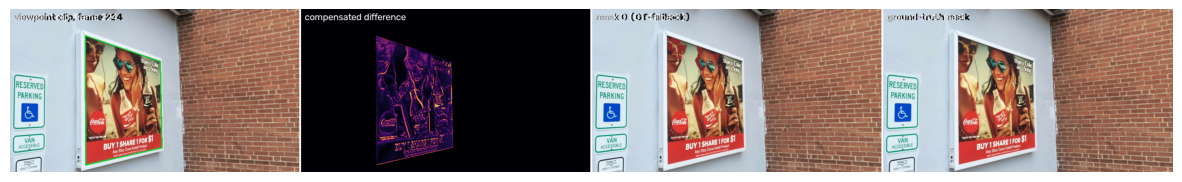

combined clip (coke_unconstrained): mean IoU 0.938  mean leakage 0.001 (baseline 0.968)  false occlusion 0.011 over 6 frames  coverage 0.938 over 6 frames  GT-fallback rows 1/6
viewpoint clip (coke_perspective): mean IoU nan  mean leakage nan (baseline nan)  false occlusion 0.021 over 3 frames  coverage 0.930 over 3 frames  GT-fallback rows 2/3
viewpoint difference diagnostic: bbox is (x_min, y_min, x_max, y_max); compare mean difference in false-occlusion vs retained board pixels
  frame 128: false fraction 0.000, mean difference false/retained nan/0.039, bbox None
  frame 224: false fraction 0.043, mean difference false/retained 0.200/0.092, bbox (166, 63, 280, 289)
  frame 288: false fraction 0.019, mean difference false/retained 0.235/0.109, bbox (130, 41, 223, 247)


In [8]:
ref_rect = sp.rect_corners(reference.shape[1], reference.shape[0]).astype(np.float32)
print(f"{'clip':>9s} {'frame':>5s} {'H':>11s} {'IoU':>6s} {'F1':>6s} {'leakage':>8s} {'base leak':>9s} {'false occ':>9s} {'coverage':>8s}")
stress_rows = {}
for level, cid in [(name, data.stress_clips(3)[name]) for name in ("combined", "viewpoint")]:
    video, _ = data.clip_paths(cid)
    gm = {f: (sp.resize_width(m.astype(np.uint8) * 255, width) > 127) for f, m in data.load_diagnostic_masks(cid).items()}
    gc = data.load_diagnostic_mask_corners(cid, scale=factor)
    fr = {i: f for i, f in sp.iter_video(video, step=1, width=width, start=min(gm), stop=max(gm) + 1) if i in gm}
    for f in sorted(fr):
        H, corners, pairs, inliers, diag = localise_board(reference, fr[f], config.localisation)
        source = "frozen"
        if H is None or not diag["status"] or metrics.corner_error(corners, gc[f]) > config.localisation.success_threshold:
            H = cv2.getPerspectiveTransform(ref_rect, gc[f].astype(np.float32)).astype(np.float64); source = "GT-fallback"
        m, dmap, comp = occlusion_mask(fr[f], H, reference, config.occlusion)
        Ha = artwork_to_frame(artwork, H, config.localisation); warped, cov = warp_artwork(artwork, Ha, fr[f].shape)
        out, alpha = composite(fr[f], warped, cov, m, config.composite)
        base, alpha_base = composite(fr[f], warped, cov, np.zeros_like(m), config.composite)
        board = sp.quad_mask(m.shape, gc[f]); visible = board & ~gm[f]
        false_pixels = m & visible
        retained_pixels = visible & ~m
        fy, fx = np.nonzero(false_pixels)
        false_bbox = ((int(fx.min()), int(fy.min()), int(fx.max()), int(fy.max()))
                      if len(fx) else None)
        row = {"clip": level, "frame": f, "H": source,
               "iou": metrics.mask_iou(m, gm[f]) if gm[f].any() else float("nan"), "f1": metrics.mask_f1(m, gm[f]) if gm[f].any() else float("nan"),
               "leakage": metrics.leakage(alpha, gm[f]), "baseline_leakage": metrics.leakage(alpha_base, gm[f]),
               "false_occlusion": float(false_pixels.sum() / max(visible.sum(), 1)),
               "false_diff_mean": float(dmap[false_pixels].mean()) if false_pixels.any() else float("nan"),
               "retained_diff_mean": float(dmap[retained_pixels].mean()) if retained_pixels.any() else float("nan"),
               "false_bbox": false_bbox,
               "coverage_visible": float(((alpha > 0.5) & visible).sum() / max(visible.sum(), 1))}
        stress_rows[(level, f)] = row
        g = lambda v, fmt="{:6.3f}": (fmt.format(v) if np.isfinite(v) else "   n/a")
        print(f"{level:>9s} {f:5d} {source:>11s} {g(row['iou'])} {g(row['f1'])} {g(row['leakage'], '{:8.3f}')} {g(row['baseline_leakage'], '{:9.3f}')} {row['false_occlusion']:9.3f} {row['coverage_visible']:8.3f}")
    show = sorted(fr)[len(fr) // 2]; H_show = stress_rows[(level, show)]
    m, dmap, _ = occlusion_mask(fr[show], cv2.getPerspectiveTransform(ref_rect, gc[show].astype(np.float32)).astype(np.float64) if H_show["H"] == "GT-fallback" else localise_board(reference, fr[show], config.localisation)[0], reference, config.occlusion)
    plt.figure(figsize=(15, 4)); plt.imshow(viz.montage([viz.label(viz.draw_quad(fr[show], gc[show]), f"{level} clip, frame {show}"), viz.label(viz.heatmap(dmap, 0.6), "compensated difference"), viz.label(viz.overlay_mask(fr[show], m), f"mask O ({H_show['H']})"), viz.label(viz.overlay_mask(fr[show], gm[show]), "ground-truth mask")], cols=4)); plt.axis("off"); plt.show()
nm = lambda xs: float(np.nanmean(xs)) if np.any(np.isfinite(xs)) else float("nan")   # nan when every entry is nan (the viewpoint clip has no foreground)
for level in ("combined", "viewpoint"):
    rows_l = [r for (lv, _), r in stress_rows.items() if lv == level]
    print(f"{level} clip ({data.stress_clips(3)[level]}): mean IoU {nm([r['iou'] for r in rows_l]):.3f}  mean leakage {nm([r['leakage'] for r in rows_l]):.3f} "
          f"(baseline {nm([r['baseline_leakage'] for r in rows_l]):.3f})  false occlusion {np.mean([r['false_occlusion'] for r in rows_l]):.3f} over {len(rows_l)} frames  coverage {np.mean([r['coverage_visible'] for r in rows_l]):.3f} over {len(rows_l)} frames  "
          f"GT-fallback rows {sum(r['H'] == 'GT-fallback' for r in rows_l)}/{len(rows_l)}")
# The viewpoint masks are empty, so every detected foreground pixel is a false occlusion.
# Compare its compensated difference with unmasked visible-board pixels and report where it occurs.
print("viewpoint difference diagnostic: bbox is (x_min, y_min, x_max, y_max); compare mean difference in false-occlusion vs retained board pixels")
for row in (r for (lv, _), r in stress_rows.items() if lv == "viewpoint"):
    print(f"  frame {row['frame']}: false fraction {row['false_occlusion']:.3f}, "
          f"mean difference false/retained {row['false_diff_mean']:.3f}/{row['retained_diff_mean']:.3f}, "
          f"bbox {row['false_bbox']}")

## 7. Optional ablation — `mode="colour"`
A colour-histogram back-projection of the board appearance as an alternative occlusion signal.

In [7]:
try:
    m_col, d_col, _ = occlusion_mask(mask_frames[i], homs[i], reference, replace(config.occlusion, mode="colour"))
    print("colour mode IoU on frame", i, ":", round(metrics.mask_iou(m_col, (masks_val | masks_test)[i]), 3))
except NotImplementedError:
    print("colour mode not implemented (optional)")

colour mode not implemented (optional)


## Reflection prompts
1. Which pixels of the card are missed, and what in the difference map explains it (hint: compare the card's colour with the poster's sky)?
2. Where does the mask leak outside the card, and is that a homography error or a difference-threshold error?
3. The card is a uniform, strongly coloured occluder. Which occluder in your own clip (an arm, a bag, a ball) would be harder, and why?
4. What would a shadow cast on the poster do to the mask, and how would you tell it apart from an occluder?
5. On the viewpoint clip the homography is correct and nothing occludes the board, yet pixels are masked. Which assumption of the differencing fails under strong perspective (**Question 4**)?